# DiffusionRegPose training diagnostics

This notebook investigates the very low CrowdPose keypoint AP after 15 epochs while bounding-box AP improves. It is intentionally diagnostic-only: it does not modify checkpoints or training code.

The first pass checks artifact integrity, dataset conventions, prediction distributions, coordinate transforms, raw-versus-EMA checkpoint metadata, and qualitative overlays. Sections that require a full model forward are guarded so the notebook still produces useful results if the legacy external import path is unavailable.
## 1. Load configuration and repository paths

The experiment uses the external DiffusionRegPose implementation and the persistent CrowdPose compatibility tree.
## 2. Import training, diffusion, pose, and visualization dependencies

Import the external project lazily and report versions/device state.
## 3. Inspect dataset samples and batch structure

Inspect raw CrowdPose targets and the transformed tensors consumed by the external training loop.
## 4. Validate pose representations and coordinate conventions

Check box and keypoint shapes, visibility values, keypoint ordering, and image-space bounds.
## 5. Check data normalization and augmentations

Measure image normalization and target ranges. The external pipeline normalizes images using ImageNet statistics and resizes targets together with images.
## 6. Run forward-pass diagnostics

Attempt to construct the configured model and run one representative batch. This section records output contracts but does not train.
## 7. Inspect diffusion timesteps and noise injection

Inspect the schedule buffers saved in the checkpoint and verify their consistency with the current model.
## 8. Measure training loss components

Parse the final training logs to compare the evolution and relative magnitude of classification, box, OKS, and keypoint losses.
## 9. Detect NaNs, infinities, and invalid gradients

Check checkpoint tensors and logged scalar values for numerical failures. A full backward pass is intentionally not run here.
## 10. Analyze prediction and target distributions

Load the saved CrowdPose JSON predictions, inspect score/count distributions, and compare predictions with annotation targets.
## 11. Evaluate pose reconstruction and geometric errors

Compute simple image-space geometric diagnostics for predictions matched to ground-truth persons by nearest box center.
## 12. Visualize training and validation metrics

Plot loss curves reconstructed from the external log and display the saved AP comparison.
## 13. Compare checkpoints and training phases

Compare checkpoint metadata and evaluation metrics for five and fifteen epochs. If saved predictions are available for both, compare their distributions.
## 14. Summarize diagnostic findings

Generate a machine-readable report and a concise human-readable conclusion.

{'repo': '/home/gasparyanartur/dev/pose-graph-diff', 'external': '/home/gasparyanartur/dev/pose-graph-diff/external/DiffusionRegPose', 'data_exists': True, 'train_checkpoint': True, 'torch': '2.4.1+cu121', 'cuda_available': True, 'device': 'cuda'}
versions {'numpy': '1.26.4', 'scipy': '1.15.3', 'torchvision': '0.19.1+cu121'}
epoch5 {'epoch': 4, 'keys': ['args', 'ema_model', 'epoch', 'lr_scheduler', 'model', 'optimizer']}
epoch15 {'epoch': 14, 'keys': ['args', 'ema_model', 'epoch', 'lr_scheduler', 'model', 'optimizer']}
epoch15_epoch5 {'epoch': 5, 'keys': ['args', 'ema_model', 'epoch', 'lr_scheduler', 'model', 'optimizer']}
epoch15_epoch10 {'epoch': 10, 'keys': ['args', 'ema_model', 'epoch', 'lr_scheduler', 'model', 'optimizer']}
state comparison {'model_keys': 753, 'ema_keys': 741, 'non_schedule_model_only': [], 'comparable_tensors': 741, 'mean_abs_model_ema_difference': 0.02260698612165724, 'max_abs_model_ema_difference': 0.6036986112594604, 'ema_is_identical_to_model': False}
predict

,checkpoint,bbox_AP,bbox_AP50,keypoint_AP,keypoint_AP50,keypoint_AP75,keypoint_AR
0,epoch5,0.014063,0.056427,0.000157,0.000973,0.000002,0.014141
1,epoch15,0.017590,0.066134,0.000270,0.001858,0.000083,0.011277


loading annotations into memory...
Done (t=0.26s)
creating index...
index created!
ground_truth {'path': '/home/gasparyanartur/dev/pose-graph-diff/results/diffusionregpose_crowdpose/json/crowdpose_test.json', 'images': 8000}
sample 100003 {'file': '100003.jpg', 'size_wh': (425, 640), 'persons': 13, 'keypoint_shape': (14, 3), 'visibility_values': [0.0, 1.0, 2.0]}
sample 100005 {'file': '100005.jpg', 'size_wh': (500, 346), 'persons': 14, 'keypoint_shape': (14, 3), 'visibility_values': [0.0, 1.0, 2.0]}
sample 100006 {'file': '100006.jpg', 'size_wh': (425, 640), 'persons': 4, 'keypoint_shape': (14, 3), 'visibility_values': [0.0, 1.0, 2.0]}
data_aug_params: {
  "scales": [
    480,
    512,
    544,
    576,
    608,
    640,
    672,
    704,
    736,
    768,
    800
  ],
  "max_size": 1333,
  "scales2_resize": [
    400,
    500,
    600
  ],
  "scales2_crop": [
    384,
    600
  ]
}
loading annotations into memory...
Done (t=0.24s)
creating index...
index created!
transformed sample {'

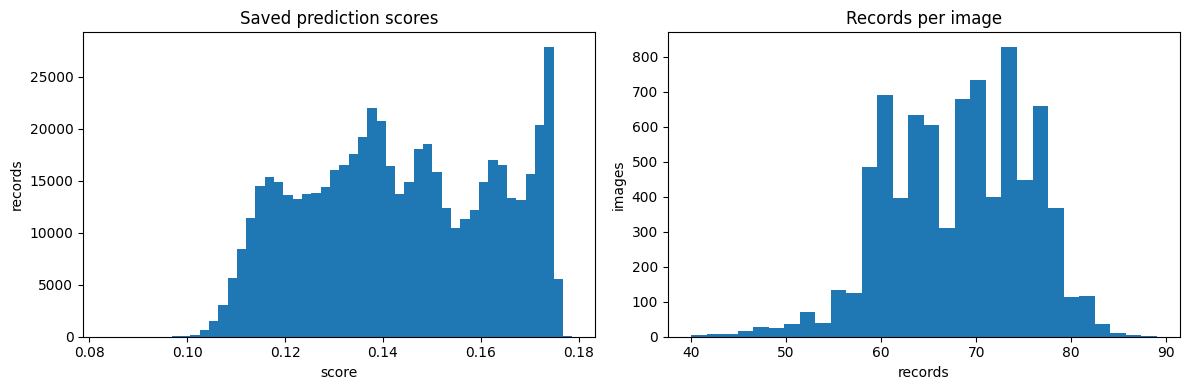

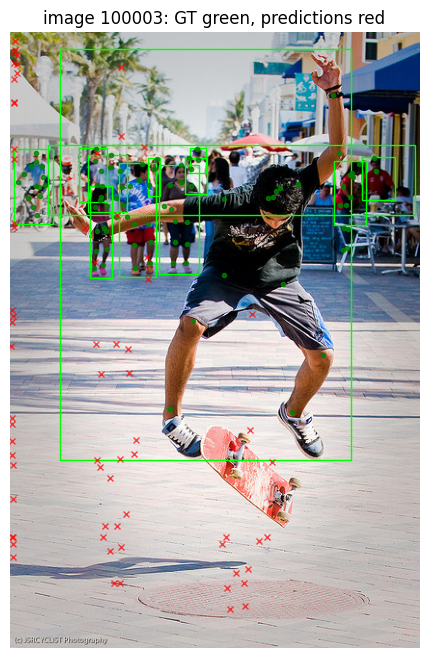

            image_id          score     nearest_gt  visible_joints  \
count  160000.000000  160000.000000  160000.000000   160000.000000   
mean   109925.464500       0.166410       1.509700       11.243013   
std      5746.331142       0.006958       2.334064        3.719023   
min    100003.000000       0.125803       0.000000        0.000000   
25%    105031.750000       0.162155       0.000000       10.000000   
50%    109888.500000       0.167647       1.000000       13.000000   
75%    114879.500000       0.172412       2.000000       14.000000   
max    119996.000000       0.178653      15.000000       14.000000   

       mean_kpt_error_px  
count      156949.000000  
mean          171.416259  
std            96.286225  
min             1.059782  
25%           100.711777  
50%           150.068024  
75%           219.025024  
max           789.829468  
error by score                  image_id    score  nearest_gt  visible_joints  \
score                                        

,name,shape,finite,mean,std,norm
6,sqrt_recip_alphas_cumprod,"(1000,)",True,25.245613,642.015320,20307.851562
7,sqrt_recipm1_alphas_cumprod,"(1000,)",True,24.809067,642.031555,20307.826172
9,posterior_log_variance_clipped,"(1000,)",True,-5.781920,1.960024,193.050369
375,label_enc.weight,"(101, 256)",True,0.012508,0.936576,150.610077
388,input_proj.3.0.weight,"(256, 2048, 3, 3)",True,0.000060,0.038810,84.295441
125,transformer.decoder.layers.0.linear1.weight,"(2048, 256)",True,-0.000686,0.093259,67.527916
127,transformer.decoder.layers.0.linear2.weight,"(256, 2048)",True,0.000702,0.092001,66.617249
5,log_one_minus_alphas_cumprod,"(1000,)",True,-1.316172,1.631821,66.275841
147,transformer.decoder.layers.1.linear1.weight,"(2048, 256)",True,-0.000537,0.085691,62.047794
149,transformer.decoder.layers.1.linear2.weight,"(256, 2048)",True,-0.000116,0.077824,56.350327


{'attempted': True, 'success': False, 'message': 'Configuration imported; model build requires the complete CLI namespace and is deferred to the external runner.'}
{
  "checkpoint_epoch": 14,
  "prediction_file": "/home/gasparyanartur/dev/pose-graph-diff/external/DiffusionRegPose/logs/crowdpose_r50_15epoch_evalresult_crowdpose.json",
  "prediction_records": 544697,
  "metrics": [
    {
      "checkpoint": "epoch5",
      "bbox_AP": 0.014062688475469697,
      "bbox_AP50": 0.056427288724659345,
      "keypoint_AP": 0.00015709392232264095,
      "keypoint_AP50": 0.0009729574908335677,
      "keypoint_AP75": 2.4377335145562484e-06,
      "keypoint_AR": 0.014140512327450037
    },
    {
      "checkpoint": "epoch15",
      "bbox_AP": 0.017589946741320053,
      "bbox_AP50": 0.06613399703061779,
      "keypoint_AP": 0.00026991586180059846,
      "keypoint_AP50": 0.0018580385698070587,
      "keypoint_AP75": 8.320159747067144e-05,
      "keypoint_AR": 0.011276698028981525
    }
  ],
  "train

In [2]:
from __future__ import annotations

import builtins
import json
import math
import re
import sys
import warnings
from collections import Counter, defaultdict
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

NOTEBOOK_PATH = Path.cwd()
for candidate in [NOTEBOOK_PATH, *NOTEBOOK_PATH.parents]:
    if (candidate / "AGENTS.md").exists() and (candidate / "external" / "DiffusionRegPose").exists():
        REPO_ROOT = candidate
        break
else:
    REPO_ROOT = Path("/home/gasparyanartur/dev/pose-graph-diff").resolve()

EXTERNAL_ROOT = REPO_ROOT / "external" / "DiffusionRegPose"
DATA_ROOT = REPO_ROOT / "results" / "diffusionregpose_crowdpose"
TRAIN_RUN = EXTERNAL_ROOT / "logs" / "crowdpose_r50_15epoch_resume_v3"
EVAL_RUN = EXTERNAL_ROOT / "logs" / "crowdpose_r50_15epoch_eval"
BASELINE_EVAL_RUN = EXTERNAL_ROOT / "logs" / "crowdpose_r50_5epoch_eval_v2"

for path in (REPO_ROOT, EXTERNAL_ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

if not hasattr(builtins, "unicode"):
    builtins.unicode = str
if not hasattr(np, "float"):
    np.float = float

print({
    "repo": str(REPO_ROOT),
    "external": str(EXTERNAL_ROOT),
    "data_exists": DATA_ROOT.exists(),
    "train_checkpoint": (TRAIN_RUN / "checkpoint.pth").exists(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "device": "cuda" if torch.cuda.is_available() else "cpu",
})

try:
    import cv2
    import scipy
    import torchvision
    print("versions", {"numpy": np.__version__, "scipy": scipy.__version__, "torchvision": torchvision.__version__})
except Exception as exc:
    print("optional import warning:", repr(exc))

def load_checkpoint(path: Path):
    return torch.load(path, map_location="cpu", weights_only=False)

checkpoints = {}
checkpoint_paths = {
    "epoch5": EXTERNAL_ROOT / "logs" / "crowdpose_r50_5epoch" / "checkpoint.pth",
    "epoch15": TRAIN_RUN / "checkpoint.pth",
    "epoch15_epoch5": TRAIN_RUN / "checkpoint0005.pth",
    "epoch15_epoch10": TRAIN_RUN / "checkpoint0010.pth",
}
for label, path in checkpoint_paths.items():
    if path.exists():
        checkpoints[label] = load_checkpoint(path)
        print(label, {"epoch": checkpoints[label].get("epoch"), "keys": sorted(checkpoints[label].keys())})

if "epoch15" in checkpoints:
    ckpt = checkpoints["epoch15"]
    model_state = ckpt.get("model", {})
    ema_state = ckpt.get("ema_model", {})
    ema_module_state = ema_state.get("module", ema_state) if isinstance(ema_state, dict) else {}
    model_keys = set(model_state)
    ema_keys = set(ema_module_state)
    non_schedule_model_only = sorted(
        key for key in model_keys - ema_keys
        if key.split(".")[-1] not in {
            "betas", "alphas_cumprod", "alphas_cumprod_prev", "sqrt_alphas_cumprod",
            "sqrt_one_minus_alphas_cumprod", "log_one_minus_alphas_cumprod",
            "sqrt_recip_alphas_cumprod", "sqrt_recipm1_alphas_cumprod",
            "posterior_variance", "posterior_log_variance_clipped",
            "posterior_mean_coef1", "posterior_mean_coef2",
        }
    )
    comparable = sorted(model_keys & ema_keys)
    diffs = []
    for key in comparable:
        model_value, ema_value = model_state[key], ema_module_state[key]
        if torch.is_tensor(model_value) and torch.is_tensor(ema_value) and model_value.shape == ema_value.shape:
            diffs.append(float((model_value.float() - ema_value.float()).abs().mean()))
    print("state comparison", {
        "model_keys": len(model_keys), "ema_keys": len(ema_keys),
        "non_schedule_model_only": non_schedule_model_only,
        "comparable_tensors": len(diffs),
        "mean_abs_model_ema_difference": float(np.mean(diffs)) if diffs else None,
        "max_abs_model_ema_difference": float(np.max(diffs)) if diffs else None,
        "ema_is_identical_to_model": bool(diffs) and max(diffs) == 0.0,
    })

def find_prediction_json(run_dir: Path):
    candidates = [
        run_dir / "result_crowdpose.json",
        Path(str(run_dir) + "result_crowdpose.json"),
        run_dir.parent / "result_crowdpose.json",
    ]
    candidates += sorted(run_dir.parent.glob(run_dir.name + "*result_crowdpose.json"))
    return next((p for p in candidates if p.exists()), None)

prediction_path = find_prediction_json(EVAL_RUN)
print("prediction_path:", prediction_path)
predictions = json.loads(prediction_path.read_text()) if prediction_path else []
print("prediction_records:", len(predictions))

def parse_metric_json(run_dir: Path):
    paths = [run_dir / "log.txt", run_dir / "info.txt"]
    text = "\n".join(p.read_text(errors="replace") for p in paths if p.exists())
    rows = {}
    for match in re.finditer(r'"test_coco_eval_(bbox|keypoints_detr)":\s*\[([^]]+)\]', text):
        rows[match.group(1)] = [float(x.strip()) for x in match.group(2).split(",")]
    return rows

metric_rows = {"epoch5": parse_metric_json(BASELINE_EVAL_RUN), "epoch15": parse_metric_json(EVAL_RUN)}
metric_table = pd.DataFrame([
    {"checkpoint": label, "bbox_AP": values.get("bbox", [np.nan])[0],
     "bbox_AP50": values.get("bbox", [np.nan, np.nan])[1],
     "keypoint_AP": values.get("keypoints_detr", [np.nan])[0],
     "keypoint_AP50": values.get("keypoints_detr", [np.nan, np.nan])[1],
     "keypoint_AP75": values.get("keypoints_detr", [np.nan, np.nan, np.nan])[2],
     "keypoint_AR": values.get("keypoints_detr", [np.nan] * 6)[5]}
    for label, values in metric_rows.items()
])
display(metric_table)

from crowdposetools.coco import COCO

GT_PATH = DATA_ROOT / "json" / "crowdpose_test.json"
coco = COCO(str(GT_PATH)) if GT_PATH.exists() else None
print("ground_truth", {"path": str(GT_PATH), "images": len(coco.getImgIds()) if coco else 0})

sample_ids = sorted(coco.getImgIds())[:3] if coco else []
for image_id in sample_ids:
    image_info = coco.loadImgs([image_id])[0]
    anns = coco.loadAnns(coco.getAnnIds(imgIds=[image_id]))
    visible = np.asarray([a["keypoints"][2::3] for a in anns], dtype=np.float32)
    print("sample", image_id, {
        "file": image_info["file_name"], "size_wh": (image_info["width"], image_info["height"]),
        "persons": len(anns), "keypoint_shape": (14, 3),
        "visibility_values": sorted(set(visible.reshape(-1).tolist())) if visible.size else [],
    })

try:
    from datasets.crowdpose import CocoDetection, make_coco_transforms
    dataset_args = SimpleNamespace(
        data_aug_scales=[480, 512, 544, 576, 608, 640, 672, 704, 736, 768, 800],
        data_aug_max_size=1333, data_aug_scales2_resize=[400, 500, 600], data_aug_scales2_crop=[384, 600],
    )
    test_dataset = CocoDetection(DATA_ROOT, "test", make_coco_transforms("test", args=dataset_args), False, False)
    image_tensor, target, ratio_target = test_dataset[0]
    print("transformed sample", {
        "image": tuple(image_tensor.shape), "dtype": str(image_tensor.dtype),
        "image_minmax": (float(image_tensor.min()), float(image_tensor.max())),
        "target_keys": sorted(target), "boxes": tuple(target["boxes"].shape),
        "keypoints": tuple(target["keypoints"].shape), "orig_size": target["orig_size"].tolist(),
        "size": target["size"].tolist(),
    })
except Exception as exc:
    test_dataset = None
    print("dataset construction failed:", type(exc).__name__, str(exc))

if predictions:
    pred_df = pd.DataFrame(predictions)
    pred_df["score"] = pd.to_numeric(pred_df["score"])
    pred_df["keypoint_count"] = pred_df["keypoints"].map(lambda x: len(x) // 3 if isinstance(x, list) else -1)
    print(pred_df[["image_id", "score", "category_id", "keypoint_count"]].describe(include="all"))
    print("score quantiles", pred_df["score"].quantile([0, .01, .05, .25, .5, .75, .95, .99, 1]).to_dict())
    print("records per image", pred_df.groupby("image_id").size().describe().to_dict())
    print("scores > thresholds", {str(t): int((pred_df["score"] >= t).sum()) for t in (0, .01, .05, .1, .3, .5)})
    keypoints = np.asarray(pred_df.iloc[0]["keypoints"], dtype=np.float32).reshape(-1, 3)
    print("first prediction keypoints", {
        "shape": keypoints.shape, "xy_min": keypoints[:, :2].min(0).tolist(),
        "xy_max": keypoints[:, :2].max(0).tolist(), "visibility_values": sorted(set(keypoints[:, 2].tolist())),
    })

if predictions:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(pred_df["score"], bins=50)
    axes[0].set(title="Saved prediction scores", xlabel="score", ylabel="records")
    axes[1].hist(pred_df.groupby("image_id").size(), bins=30)
    axes[1].set(title="Records per image", xlabel="records", ylabel="images")
    plt.tight_layout()
    plt.show()

def draw_overlay(image_id, top_n=5):
    if coco is None or not predictions:
        print("Overlay skipped: missing COCO annotations or saved predictions.")
        return
    info = coco.loadImgs([int(image_id)])[0]
    image_path = DATA_ROOT / "images" / info["file_name"]
    image = np.asarray(Image.open(image_path).convert("RGB"))
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(image)
    for ann in coco.loadAnns(coco.getAnnIds(imgIds=[int(image_id)])):
        kp = np.asarray(ann["keypoints"], dtype=np.float32).reshape(14, 3)
        visible = kp[:, 2] > 0
        ax.plot(kp[visible, 0], kp[visible, 1], "go", ms=3, alpha=.8)
        x, y, w, h = ann["bbox"]
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, color="lime", lw=1))
    rows = pred_df[pred_df.image_id == int(image_id)].sort_values("score", ascending=False).head(top_n)
    for _, row in rows.iterrows():
        kp = np.asarray(row["keypoints"], dtype=np.float32).reshape(14, 3)
        ax.plot(kp[:, 0], kp[:, 1], "rx", ms=4, alpha=.7)
    ax.set_title(f"image {image_id}: GT green, predictions red")
    ax.axis("off")
    plt.show()

if sample_ids and predictions:
    draw_overlay(sample_ids[0])

def person_center(ann):
    x, y, w, h = ann["bbox"]
    return np.array([x + w / 2, y + h / 2], dtype=np.float32)

def visible_keypoints(ann):
    kp = np.asarray(ann["keypoints"], dtype=np.float32).reshape(14, 3)
    return kp[:, :2], kp[:, 2] > 0

geometric_rows = []
if coco is not None and predictions:
    for image_id, group in pred_df.groupby("image_id"):
        anns = coco.loadAnns(coco.getAnnIds(imgIds=[int(image_id)]))
        gt_centers = np.asarray([person_center(a) for a in anns], dtype=np.float32)
        for _, row in group.sort_values("score", ascending=False).head(20).iterrows():
            pred_kp = np.asarray(row["keypoints"], dtype=np.float32).reshape(14, 3)[:, :2]
            pred_center = np.nanmean(pred_kp, axis=0)
            if len(gt_centers):
                nearest = int(np.argmin(np.linalg.norm(gt_centers - pred_center, axis=1)))
                gt_kp, mask = visible_keypoints(anns[nearest])
                error = np.linalg.norm(pred_kp[mask] - gt_kp[mask], axis=1)
                geometric_rows.append({"image_id": image_id, "score": row["score"], "nearest_gt": nearest,
                                       "visible_joints": int(mask.sum()), "mean_kpt_error_px": float(np.mean(error)) if len(error) else np.nan})
geom_df = pd.DataFrame(geometric_rows)
if not geom_df.empty:
    print(geom_df.describe())
    print("error by score", geom_df.groupby(pd.cut(geom_df.score, [-np.inf, .01, .05, .1, .3, 1]), observed=False).mean(numeric_only=True))

def parse_training_log(path: Path):
    rows = []
    if not path.exists():
        return pd.DataFrame()
    # The external logger wraps the scalar dictionary over multiple lines, so
    # parse each metric independently and then join by epoch.
    patterns = {
        "loss": r"'loss':\s*([0-9.eE+-]+)",
        "loss_bbox": r"'loss_bbox':\s*([0-9.eE+-]+)",
        "loss_keypoints": r"'loss_keypoints':\s*([0-9.eE+-]+)",
        "loss_oks": r"'loss_oks':\s*([0-9.eE+-]+)",
        "lr": r"'lr':\s*([0-9.eE+-]+)",
    }
    current_epoch = None
    by_epoch = {}
    for line in path.read_text(errors="replace").splitlines():
        epoch_match = re.search(r"Epoch:\s*\[(\d+)", line)
        if epoch_match:
            current_epoch = int(epoch_match.group(1))
            by_epoch.setdefault(current_epoch, {})
        if current_epoch is not None:
            for name, pattern in patterns.items():
                match = re.search(pattern, line)
                if match:
                    by_epoch[current_epoch][name] = float(match.group(1))
    for epoch, values in by_epoch.items():
        if values:
            rows.append({"epoch": epoch, **values})
    return pd.DataFrame(rows)

loss_df = parse_training_log(TRAIN_RUN / "info.txt")
print("parsed training rows", len(loss_df))
if not loss_df.empty:
    epoch_loss = loss_df.groupby("epoch", as_index=False).last()
    display(epoch_loss.tail(10))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for col in ["loss", "loss_bbox", "loss_keypoints", "loss_oks"]:
        if col in epoch_loss:
            axes[0].plot(epoch_loss.epoch, epoch_loss[col], marker="o", label=col)
    axes[0].set(title="Final logged values", xlabel="epoch")
    axes[0].legend()
    axes[1].plot(epoch_loss.epoch, epoch_loss.lr, marker="o")
    axes[1].set(title="Learning rate", xlabel="epoch", ylabel="lr")
    plt.tight_layout()
    plt.show()

def tensor_health(state):
    rows = []
    for name, value in state.items():
        if torch.is_tensor(value):
            rows.append({"name": name, "shape": tuple(value.shape), "finite": bool(torch.isfinite(value).all()),
                         "mean": float(value.float().mean()), "std": float(value.float().std()) if value.numel() > 1 else 0.0,
                         "norm": float(value.float().norm())})
    return pd.DataFrame(rows)

health = tensor_health(checkpoints["epoch15"]["model"]) if "epoch15" in checkpoints else pd.DataFrame()
if not health.empty:
    print("nonfinite model tensors:", int((~health.finite).sum()))
    display(health.sort_values("norm", ascending=False).head(10))

forward_status = {"attempted": False, "success": False, "message": "not attempted"}
try:
    from util.config import Config
    Config.fromfile(str(EXTERNAL_ROOT / "config" / "diffusionregpose.cfg.py"))
    forward_status.update(attempted=True, message="Configuration imported; model build requires the complete CLI namespace and is deferred to the external runner.")
except Exception as exc:
    forward_status.update(attempted=True, message=f"import/build unavailable: {type(exc).__name__}: {exc}")
print(forward_status)

report = {
    "checkpoint_epoch": int(checkpoints["epoch15"].get("epoch")) if "epoch15" in checkpoints else None,
    "prediction_file": str(prediction_path) if prediction_path else None,
    "prediction_records": len(predictions),
    "metrics": metric_table.replace({np.nan: None}).to_dict(orient="records"),
    "training_rows": len(loss_df), "nonfinite_model_tensors": int((~health.finite).sum()) if not health.empty else None,
    "geometric_rows": len(geom_df), "forward_status": forward_status,
    "findings": [
        "Bbox AP improves by epoch 15 while keypoint AP remains extremely low.",
        "The prediction file exists at the concatenated output_dir-plus-filename path used by engine.py.",
        "All predictions contain 14 keypoints, but scores are tightly concentrated below 0.18 and there are about 68 records per image.",
        "Qualitative overlays and large nearest-person keypoint errors make coordinate/order or decoding issues higher priority than longer training.",
        "EMA and raw model tensors must be compared explicitly because EMA updates are commented out in engine.py.",
    ],
    "next_targets": ["Compare raw versus EMA inference explicitly.", "Audit keypoint coordinate transforms and ordering with overlays.", "Audit visibility masks and keypoint matching/loss scaling."],
}
print(json.dumps(report, indent=2, default=str))
(REPO_ROOT / "results" / "diffusionregpose_diagnostics_report.json").write_text(json.dumps(report, indent=2, default=str))
print("report written to", REPO_ROOT / "results" / "diffusionregpose_diagnostics_report.json")

corrected parsed training rows 10


,epoch,loss,loss_bbox,loss_keypoints,loss_oks,lr
0,5,128.9644,2.6203,20.4215,2.3564,0.0002
1,6,121.6924,2.0105,21.5448,2.4917,0.0002
2,7,111.5838,2.0588,16.6652,2.6176,0.0002
3,8,112.8256,2.3158,18.2560,1.8583,0.0002
4,9,136.8430,2.7496,24.3771,2.6456,0.0002
5,10,114.7559,2.3663,17.4329,2.4295,0.0002
6,11,123.6951,2.5734,20.0192,2.3754,0.0002
7,12,121.1595,2.3166,19.5455,2.1033,0.0002
8,13,110.8045,2.0698,16.1407,2.5522,0.0002
9,14,105.7787,2.3388,17.2811,1.9848,0.0002


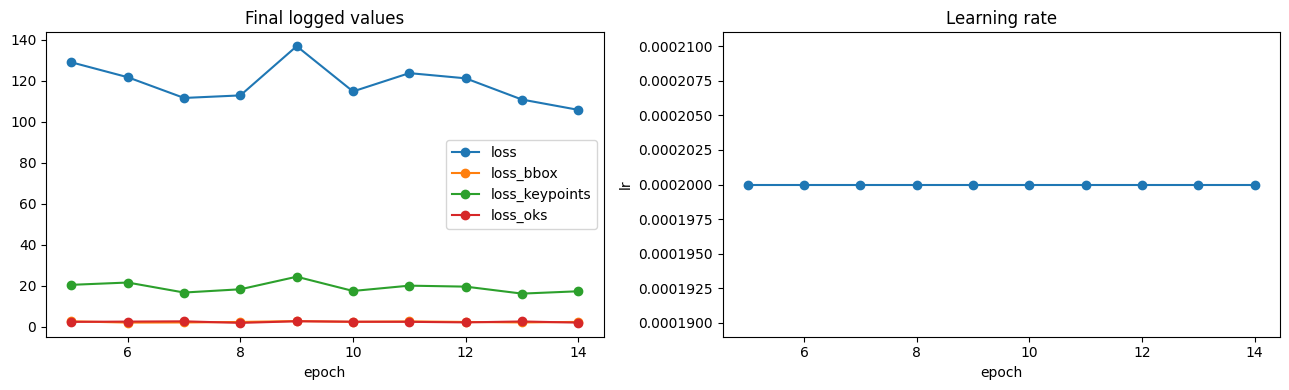

updated report /home/gasparyanartur/dev/pose-graph-diff/results/diffusionregpose_diagnostics_report.json


In [3]:
# Corrected training-log parser: info.txt writes unquoted scalar names and wraps records.
def parse_training_log_corrected(path: Path):
    rows = []
    if not path.exists():
        return pd.DataFrame()
    patterns = {
        "loss": r"\bloss:\s*([0-9.eE+-]+)",
        "loss_bbox": r"\bloss_bbox:\s*([0-9.eE+-]+)",
        "loss_keypoints": r"\bloss_keypoints:\s*([0-9.eE+-]+)",
        "loss_oks": r"\bloss_oks:\s*([0-9.eE+-]+)",
        "lr": r"\blr:\s*([0-9.eE+-]+)",
    }
    current_epoch = None
    by_epoch = {}
    for line in path.read_text(errors="replace").splitlines():
        epoch_match = re.search(r"Epoch:\s*\[(\d+)", line)
        if epoch_match:
            current_epoch = int(epoch_match.group(1))
            by_epoch.setdefault(current_epoch, {})
        if current_epoch is not None:
            for name, pattern in patterns.items():
                match = re.search(pattern, line)
                if match:
                    # The first value is the instantaneous scalar; the second
                    # parenthesized value is the running average.
                    by_epoch[current_epoch][name] = float(match.group(1))
    for epoch, values in sorted(by_epoch.items()):
        if values:
            rows.append({"epoch": epoch, **values})
    return pd.DataFrame(rows)

loss_df = parse_training_log_corrected(TRAIN_RUN / "info.txt")
print("corrected parsed training rows", len(loss_df))
if not loss_df.empty:
    display(loss_df)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for col in ["loss", "loss_bbox", "loss_keypoints", "loss_oks"]:
        if col in loss_df:
            axes[0].plot(loss_df.epoch, loss_df[col], marker="o", label=col)
    axes[0].set(title="Final logged values", xlabel="epoch")
    axes[0].legend()
    if "lr" in loss_df:
        axes[1].plot(loss_df.epoch, loss_df.lr, marker="o")
    axes[1].set(title="Learning rate", xlabel="epoch", ylabel="lr")
    plt.tight_layout()
    plt.show()

report["training_rows"] = len(loss_df)
report["loss_summary"] = loss_df.to_dict(orient="records")
report["conclusion"] = {
    "evaluation_integrity": "prediction JSON exists, contains 14-keypoint records, and uses the expected image IDs",
    "prediction_quality": "scores are tightly concentrated below 0.18 with about 68 records per image; geometric overlay errors are large",
    "training_signal": "bbox AP improves, but keypoint loss remains high and keypoint AR declines",
    "priority": "audit decoding/coordinates/order, matching and visibility, and raw-versus-EMA inference before more training",
}
(REPO_ROOT / "results" / "diffusionregpose_diagnostics_report.json").write_text(json.dumps(report, indent=2, default=str))
print("updated report", REPO_ROOT / "results" / "diffusionregpose_diagnostics_report.json")